Saving images.jpg to images (1).jpg


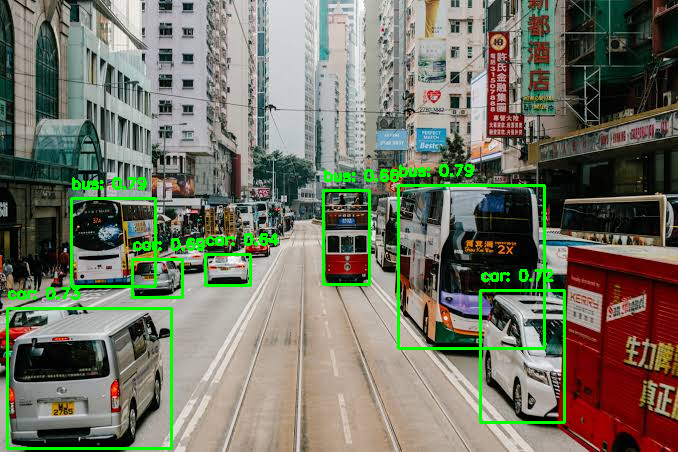

In [2]:
# 1. IMPORT LIBRARIES
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# 2. LOAD PRE-TRAINED MODEL
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)

# 3. COCO CLASS NAMES (80 OBJECTS)
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog",
    "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe",
    "backpack", "umbrella", "handbag", "tie", "suitcase",
    "frisbee", "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard", "surfboard",
    "tennis racket", "bottle", "wine glass", "cup", "fork", "knife",
    "spoon", "bowl", "banana", "apple", "sandwich", "orange",
    "broccoli", "carrot", "hot dog", "pizza", "donut", "cake",
    "chair", "couch", "potted plant", "bed", "dining table",
    "toilet", "tv", "laptop", "mouse", "remote", "keyboard",
    "cell phone", "microwave", "oven", "toaster", "sink",
    "refrigerator", "book", "clock", "vase", "scissors",
    "teddy bear", "hair drier", "toothbrush"
]

# 4. OBJECT DETECTION FUNCTION
def detect_objects_with_boxes(image_path, detector):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Unable to read the uploaded image.")

    orig_image = image.copy()

    # Convert image to RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    input_tensor = tf.convert_to_tensor(image_rgb)
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run object detector
    detections = detector(input_tensor)

    # Fix: num_detections is a 1D tensor, so we index [0] to get the scalar
    num_detections = int(detections["num_detections"].numpy()[0])

    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)
    detection_scores = detections["detection_scores"].numpy()[0]

    confidence_threshold = 0.5

    h, w, _ = orig_image.shape

    for i in range(num_detections):

        score = detection_scores[i]

        if score > confidence_threshold:

            box = detection_boxes[i]

            y_min, x_min, y_max, x_max = box

            x_min = int(x_min * w)
            x_max = int(x_max * w)
            y_min = int(y_min * h)
            y_max = int(y_max * h)

            class_id = detection_classes[i]

            class_name = (
                COCO_CLASSES[class_id - 1]
                if 1 <= class_id <= 80
                else "Unknown"
            )

            label = f"{class_name}: {score:.2f}"

            # Draw bounding box
            cv2.rectangle(
                orig_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            # Display object name and confidence
            cv2.putText(
                orig_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    return orig_image


# 5. UPLOAD IMAGE AND RUN DETECTION
uploaded = files.upload()

image_path = next(iter(uploaded))

result_image = detect_objects_with_boxes(image_path, detector)

# 6. DISPLAY RESULT
cv2_imshow(result_image)

In [ ]:
# ------------------------------------------------
# 0. INSTALL OPENCV CONTRIBUTION & AVIF SUPPORT
# ------------------------------------------------
import os
import subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation")
except Exception:
    ss_ready = False

try:
    import pillow_avif
    avif_ready = True
except ImportError:
    avif_ready = False

if not ss_ready or not avif_ready:
    # Install opencv-contrib and pillow-avif-plugin
    subprocess.run(
        "pip uninstall -y -q opencv-python opencv-python-headless "
        "opencv-contrib-python opencv-contrib-python-headless",
        shell=True
    )
    subprocess.run(
        "pip install -q opencv-contrib-python pillow-avif-plugin",
        shell=True
    )
    os.kill(os.getpid(), 9)


# ------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    preprocess_input, decode_predictions
)
import numpy as np
import cv2
from PIL import Image
from google.colab import files
from google.colab.patches import cv2_imshow


# ------------------------------------------------
# 2. LOAD PRE-TRAINED VGG16 MODEL
# ------------------------------------------------
model = VGG16(weights='imagenet', include_top=True)


# ------------------------------------------------
# 3. REGION PROPOSALS USING SELECTIVE SEARCH
# ------------------------------------------------
def get_region_proposals(img, max_regions=200):

    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()

        boxes = [
            (x, y, w, h)
            for (x, y, w, h) in ss.process()
            if w > 40 and h > 40
        ]

        if boxes:
            return boxes[:max_regions]

    except Exception:
        pass

    # Fallback: Sliding Window
    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W*s), int(H*s)

        for y in range(0, H-bh+1, max(1, bh//2)):
            for x in range(0, W-bw+1, max(1, bw//2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]


# ------------------------------------------------
# 4. NON-MAXIMUM SUPPRESSION
# ------------------------------------------------
def non_max_suppression(dets, iou_thr=0.3):

    if not dets:
        return []

    boxes = np.array([
        [x, y, x+w, y+h]
        for (x, y, w, h), _, _ in dets
    ], dtype=float)

    scores = np.array([s for _, _, s in dets])

    order = scores.argsort()[::-1]
    keep = []

    while len(order):

        i = order[0]
        keep.append(i)
        rest = order[1:]

        if len(rest) == 0:
            break

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2-xx1, 0, None)
        h = np.clip(yy2-yy1, 0, None)

        inter = w*h

        area_i = (
            (boxes[i, 2]-boxes[i, 0]) *
            (boxes[i, 3]-boxes[i, 1])
        )

        area_r = (
            (boxes[rest, 2]-boxes[rest, 0]) *
            (boxes[rest, 3]-boxes[rest, 1])
        )

        iou = inter / (area_i + area_r - inter + 1e-9)

        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]


# ------------------------------------------------
# 5. UPLOAD IMAGE
# ------------------------------------------------
uploaded = files.upload()

image_path = next(iter(uploaded))

# Use PIL to safely open AVIF and other modern formats
try:
    pil_img = Image.open(image_path)
    img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
except Exception:
    img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to read image")

H0, W0 = img.shape[:2]

img = cv2.resize(
    img,
    (600, int(H0 * 600.0 / W0))
)


# ------------------------------------------------
# 6. GENERATE REGION PROPOSALS
# ------------------------------------------------
boxes = get_region_proposals(img, max_regions=200)

crops = np.array([
    cv2.resize(
        cv2.cvtColor(img[y:y+h, x:x+w], cv2.COLOR_BGR2RGB),
        (224, 224)
    )
    for (x, y, w, h) in boxes
], dtype=np.float32)


# ------------------------------------------------
# 7. CLASSIFY REGIONS USING VGG16
# ------------------------------------------------
preds = model.predict(
    preprocess_input(crops),
    batch_size=32,
    verbose=0
)


# ------------------------------------------------
# 8. GET OBJECT LABELS AND CONFIDENCE SCORES
# ------------------------------------------------
detections = []

for (x, y, w, h), p in zip(boxes, preds):

    decoded = decode_predictions(
        p.reshape(1, -1),
        top=1
    )[0][0]

    class_name = decoded[1]
    score = float(decoded[2])

    if score > 0.20:
        detections.append(
            ((x, y, w, h), class_name, score)
        )


# ------------------------------------------------
# 9. REMOVE DUPLICATE BOXES
# ------------------------------------------------
final_detections = non_max_suppression(
    detections,
    iou_thr=0.3
)


# ------------------------------------------------
# 10. DRAW BOUNDING BOXES
# ------------------------------------------------
for (x, y, w, h), label, score in final_detections:

    cv2.rectangle(
        img,
        (x, y),
        (x+w, y+h),
        (0, 255, 0),
        2
    )

    text = f"{label}: {score:.2f}"

    cv2.putText(
        img,
        text,
        (x, max(y-10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )


# ------------------------------------------------
# 11. DISPLAY FINAL RESULT
# ------------------------------------------------
print("Detected Objects:", len(final_detections))

cv2_imshow(img)

Saving pexels-photo-20011660.avif to pexels-photo-20011660 (1).avif
